In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cmcrameri import cm

# ------------------------------------------------------------
# Load mean IWC profile data
# ------------------------------------------------------------


In [2]:
df = pd.read_parquet("mean_iwc_by_height_data.parquet")

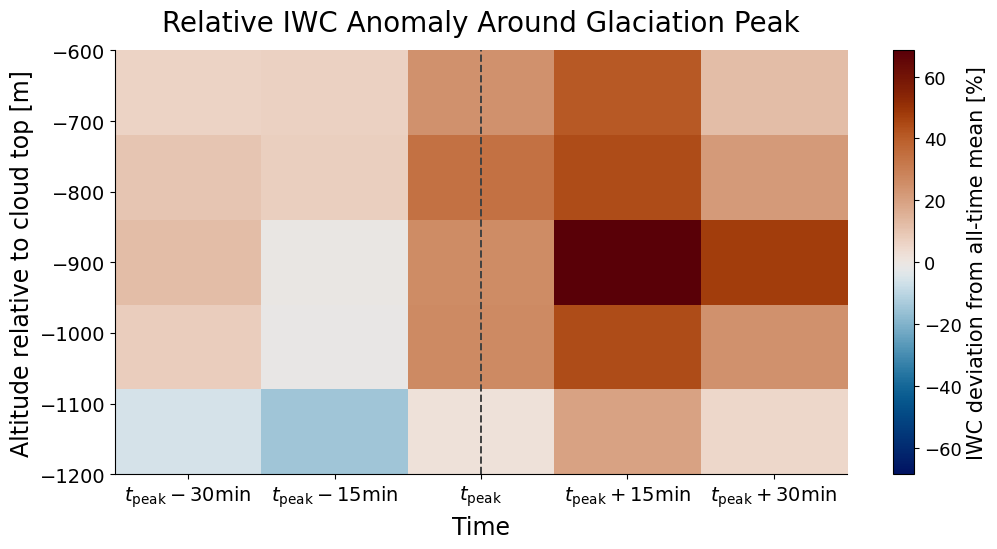

In [3]:
from matplotlib.colors import TwoSlopeNorm

# Times to plot, in minutes relative to glaciation peak
target_times = [-30, -15, 0, 15, 30]

# Keep only requested times
plot_df = (
    df[df["rel_time_min"].isin(target_times)]
    .copy()
    .sort_values("rel_time_min")
)

# Safety check
missing = sorted(set(target_times) - set(plot_df["rel_time_min"]))
if missing:
    print(f"Warning: missing requested relative times: {missing}")

# ------------------------------------------------------------
# Convert stored profiles to a 2D array
# Shape: time x height
# ------------------------------------------------------------
profiles = np.stack(
    plot_df["mean_iwc_profile"].apply(lambda x: np.asarray(x, dtype=float)).values
)

times = plot_df["rel_time_min"].values

# ------------------------------------------------------------
# Compute all-time mean profile
# This uses every rel_time_min available in mean_iwc_by_height_data,
# not only the five selected times.
# ------------------------------------------------------------
all_profiles = np.stack(
    df["mean_iwc_profile"].apply(lambda x: np.asarray(x, dtype=float)).values
)

all_time_mean_profile = np.nanmean(all_profiles, axis=0)

# ------------------------------------------------------------
# Deviation from all-time mean profile
# Absolute anomaly:
#     anomaly = IWC(time, height) - mean_IWC(height)
# ------------------------------------------------------------
iwc_anomaly = profiles - all_time_mean_profile

# Optional: percentage deviation instead
# Be careful where all_time_mean_profile is zero or very small.
iwc_anomaly = 100 * (profiles - all_time_mean_profile) / all_time_mean_profile
iwc_anomaly[~np.isfinite(iwc_anomaly)] = np.nan

# ------------------------------------------------------------
# Height axis
# Height bins correspond to altitude relative to cloud top:
# 0 m at cloud top, negative values below cloud top.
# Your selected profile spans -600 m to -1200 m below cloud top.
# ------------------------------------------------------------
height_relative_to_cth = np.linspace(-1200, -600, iwc_anomaly.shape[1])

# ------------------------------------------------------------
# Plot heatmap
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10.5, 5.6))

# Transparent background
fig.patch.set_alpha(0)
ax.set_facecolor("none")

absmax = np.nanmax(np.abs(iwc_anomaly))
norm = TwoSlopeNorm(vmin=-absmax, vcenter=0, vmax=absmax)

im = ax.imshow(
    iwc_anomaly.T,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap=cm.vik,      # better for symmetric positive/negative anomalies
    norm=norm,
    extent=[
        times.min() - 7.5,
        times.max() + 7.5,
        height_relative_to_cth.min(),
        height_relative_to_cth.max(),
    ],
)

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("IWC deviation from all-time mean [%]", fontsize=15)
cbar.ax.tick_params(labelsize=13)

ax.set_title(
    "Relative IWC Anomaly Around Glaciation Peak",
    fontsize=20,
    pad=14,
)

ax.set_xlabel("Time", fontsize=17)
ax.set_ylabel("Altitude relative to cloud top [m]", fontsize=17)

ax.set_xticks(target_times)
ax.set_xticklabels(
    [
        r"$t_{\mathrm{peak}} - 30\mathrm{min}$",
        r"$t_{\mathrm{peak}} - 15\mathrm{min}$",
        r"$t_{\mathrm{peak}}$",
        r"$t_{\mathrm{peak}} + 15\mathrm{min}$",
        r"$t_{\mathrm{peak}} + 30\mathrm{min}$",
    ],
    fontsize=14,
)

ax.tick_params(axis="y", labelsize=14)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1.4,
    color="0.25",
)

# Remove top and right axes, like your reference figure
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "relative_iwc_anomaly_heatmap_symmetric.png",
    transparent=True,
    bbox_inches="tight",
    dpi=300,
)

plt.show()